# Jack’s Car Rental — Value Iteration

This notebook formulates the two-location car rental problem as a finite Markov decision process (MDP) and solves it using synchronous value iteration. Exact inventory-capped Poisson distributions are used to precompute transition probabilities.

## 1. Problem formulation

| Parameter | Location A | Location B |
|---|---:|---:|
| Maximum inventory | 20 | 20 |
| Mean daily rental requests | 3 | 4 |
| Mean daily returns | 3 | 2 |

Each rental earns 10 dollars, each overnight transfer costs 2 dollars, and at most five cars may be transferred per night. The discount factor is $\gamma=0.9$. Rental requests and returns are independent Poisson variables.

### State and action spaces

Let $s=(i,j)$ denote the inventories at A and B before overnight transfers. With capacity $C=20$,

$$\mathcal S=\{0,\ldots,C\}^2,\qquad |\mathcal S|=441.$$

A positive action $a$ transfers cars from A to B; a negative action transfers cars in the opposite direction. The post-transfer inventories are $u=i-a$ and $v=j+a$. With transfer limit $M=5$, the feasible action set is

$$\mathcal A(i,j)=\{a\in\mathbb Z: |a|\le M,\ 0\le i-a\le C,\ 0\le j+a\le C\}.$$

These constraints prevent transfers that exceed either the available inventory or the destination capacity.

The objective is to maximize the expected discounted sum of rental revenue minus transfer costs:

$$V^*(s)=\sup_\pi \mathbb E_\pi\left[\sum_{t=0}^{\infty}\gamma^t R_t\mid S_0=s\right].$$

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson

## 2. Environment and transition probabilities

### 2.1 Inventory-capped Poisson distributions

For $X\sim\operatorname{Poisson}(\lambda)$, the probability mass function is

$$p_\lambda(k)=e^{-\lambda}\frac{\lambda^k}{k!},\qquad k=0,1,\ldots.$$

For a nonnegative integer cap $c$, define $Y=\min(X,c)$. Its distribution is

$$\Pr(Y=k)=\begin{cases}
p_\lambda(k),&0\le k<c,\\
\Pr(X\ge c),&k=c,\\
0,&\text{otherwise}.
\end{cases}$$

The final probability is computed using `poisson.sf(c - 1, rate)`. This includes the entire tail, including the case $c=0$, without an arbitrary truncation tolerance.

### 2.2 Single-location dynamics and rewards

For location $\ell\in\{A,B\}$ with post-transfer inventory $x$, let $D_\ell$ and $U_\ell$ denote independent rental requests and returns. The number rented is $L_\ell=\min(D_\ell,x)$, and the next inventory is

$$X'_\ell=\min(C,x-L_\ell+U_\ell).$$

The expected rental revenue is

$$r_\ell(x)=10\sum_{k=0}^{x} k\Pr(L_\ell=k).$$

The transition matrix is obtained by conditioning on the number rented:

$$P_\ell(x,y)=\sum_{k=0}^{x}\Pr(L_\ell=k)\Pr\bigl(\min(C,x-k+U_\ell)=y\bigr).$$

Every row of $P_\ell$ sums to one. Returns above the available capacity are aggregated at inventory $C$.

### 2.3 Joint transitions and vectorized Bellman action values

Independence between locations gives

$$\Pr((i',j')\mid(i,j),a)=P_A(i-a,i')P_B(j+a,j').$$

For a value function $V$, the expected return of a feasible action is

$$Q_V((i,j),a)=r_A(u)+r_B(v)-2|a|+\gamma\sum_{i'=0}^{C}\sum_{j'=0}^{C}P_A(u,i')P_B(v,j')V(i',j').$$

The double sum for every post-transfer inventory pair is computed simultaneously as the matrix product

$$H=P_A V P_B^\top.$$

The implementation precomputes the two transition matrices, expected rewards and feasible action indices. This avoids recomputing Poisson probabilities during each Bellman sweep. Infeasible actions receive value $-\infty$ so they cannot be selected by maximization.

In [5]:
class JackCarRental:
    """Finite two-location rental MDP with precomputed transitions"""
    def __init__(self, capacity=20, max_move=5, rental_reward=10,
                 move_cost=2, request_rates=(3, 4), return_rates=(3, 2)):
        if not isinstance(capacity, int) or capacity < 1:
            raise ValueError("capacity must be a positive integer")
        if not isinstance(max_move, int) or max_move < 0:
            raise ValueError("max_move must be a nonnegative integer")
        if len(request_rates) != 2 or len(return_rates) != 2:
            raise ValueError("Provide two request and two return rates")
        if not all(np.isfinite(x) and x >= 0 for x in (*request_rates, *return_rates, rental_reward, move_cost)):
            raise ValueError("Rates, reward and cost must be finite and nonnegative")
        self.capacity = capacity
        self.max_move = max_move
        self.rental_reward = rental_reward
        self.move_cost = move_cost
        self.P_a, self.r_a = self._location_model(request_rates[0], return_rates[0])
        self.P_b, self.r_b = self._location_model(request_rates[1], return_rates[1])
        self.actions = np.arange(-max_move, max_move + 1)
        i, j = np.indices((capacity + 1, capacity + 1))
        a = self.actions[:, None, None]
        self.post_a = i[None, :, :] - a
        self.post_b = j[None, :, :] + a
        self.feasible = ((self.post_a >= 0) & (self.post_a <= capacity) &
                         (self.post_b >= 0) & (self.post_b <= capacity))
        # Safe indices for vectorization only; infeasible actions are masked out.
        self.post_a = np.clip(self.post_a, 0, capacity)
        self.post_b = np.clip(self.post_b, 0, capacity)

    @staticmethod
    def capped_poisson(rate, cap):
        """Distribution of min(Poisson(rate), cap), including the full tail"""
        return np.r_[poisson.pmf(np.arange(cap), rate), poisson.sf(cap - 1, rate)]

    def _location_model(self, request_rate, return_rate):
        """Return transition matrix and expected rental rewards by inventory"""
        P = np.zeros((self.capacity + 1, self.capacity + 1))
        reward = np.zeros(self.capacity + 1)
        for stock in range(self.capacity + 1):
            demand = self.capped_poisson(request_rate, stock)
            reward[stock] = self.rental_reward * np.dot(np.arange(stock + 1), demand)
            for rented, probability in enumerate(demand):
                remaining = stock - rented
                returns = self.capped_poisson(return_rate, self.capacity - remaining)
                P[stock, remaining:] += probability * returns
        return P, reward

    def feasible_actions(self, state):
        """Return feasible actions from a given state"""
        i, j = state
        return self.actions[self.feasible[:, i, j]]

    def action_values(self, value, gamma):
        """Compute all Bellman action values using precomputed transitions"""
        continuation = self.P_a @ value @ self.P_b.T
        post_value = self.r_a[:, None] + self.r_b[None, :] + gamma * continuation
        q = post_value[self.post_a, self.post_b] - self.move_cost * np.abs(self.actions[:, None, None])
        return np.where(self.feasible, q, -np.inf)

## 3. Synchronous value iteration

Define the Bellman optimality operator by

$$(TV)(s)=\max_{a\in\mathcal A(s)}Q_V(s,a).$$

Starting with $V_0(s)=0$, synchronous value iteration computes

$$V_{k+1}=TV_k.$$

All states are updated using the same previous value function. Since $\gamma<1$, the operator is a contraction in the supremum norm:

$$\|TV-TW\|_\infty\le\gamma\|V-W\|_\infty.$$

Consequently, the iterates converge to the unique optimal value function.

### 3.1 Stopping criterion and policy extraction

The implementation tracks the maximum absolute change

$$\delta_k=\|V_{k+1}-V_k\|_\infty.$$

Iteration stops when $\delta_k<\varepsilon$, with default tolerance $\varepsilon=0.01$, or when the maximum number of sweeps is reached. The greedy policy is

$$\pi_V(s)\in\arg\max_{a\in\mathcal A(s)}Q_V(s,a).$$

Intermediate greedy policies are printed every ten sweeps by default (`print_every=10`); setting this argument to zero disables printing.

### 3.2 Bellman residual

After termination, the code computes

$$\rho=\|TV-V\|_\infty.$$

The contraction property yields the a posteriori error bound

$$\|V-V^*\|_\infty\le\frac{\rho}{1-\gamma}.$$

The residual is therefore a useful numerical diagnostic; a finite tolerance produces an approximate solution rather than a proof of exact optimality.

In [8]:
class ValueIteration:
    """Solve Jack's Car Rental MDP using synchronous value iteration"""

    def __init__(self, environment, gamma=0.9, tolerance=0.01,
                 max_iterations=1000):

        if not np.isfinite(gamma) or not 0 <= gamma < 1:
            raise ValueError("gamma must be in [0, 1)")
        if not np.isfinite(tolerance) or tolerance <= 0:
            raise ValueError("tolerance must be finite and positive")
        if not isinstance(max_iterations, int) or max_iterations < 1:
            raise ValueError("max_iterations must be a positive integer")

        self.env = environment
        self.gamma = gamma
        self.tolerance = tolerance
        self.max_iterations = max_iterations

    def solve(self, print_every=10):
        """Estimate the optimal value function and extract its greedy policy"""

        if not isinstance(print_every, int) or print_every < 0:
            raise ValueError("print_every must be a nonnegative integer")

        shape = (self.env.capacity + 1,) * 2
        self.value = np.zeros(shape)
        self.history = []
        self.converged = False

        for ite in range(self.max_iterations):

            # Synchronous Bellman optimality update
            updated = self.env.action_values(self.value, self.gamma).max(axis=0)

            # Track convergence using the supremum norm
            delta = float(np.max(np.abs(updated - self.value)))
            self.history.append(delta)
            self.value = updated

            # Display the intermediate greedy policy
            if print_every and (ite + 1) % print_every == 0:
                q_current = self.env.action_values(self.value, self.gamma)
                policy = self.env.actions[np.argmax(q_current, axis=0)]

                print(f"After {ite + 1} iterations, the policy matrix is:")
                print("-" * 62)
                print(policy)
                print("-" * 62)

            if delta < self.tolerance:
                self.converged = True
                break

        # Extract the greedy policy from the final value function
        q = self.env.action_values(self.value, self.gamma)
        self.policy = self.env.actions[np.argmax(q, axis=0)]

        # Compute the Bellman residual
        self.residual = float(np.max(np.abs(q.max(axis=0) - self.value)))

        return self.value, self.policy

## 4. Run and validate the solution

The following cell solves the MDP and checks that the transition matrices are nonnegative and row-stochastic, that the selected transfers respect both inventory and movement constraints, and that the value function is finite.

The printed diagnostics report convergence status, number of sweeps, Bellman residual and the estimated value of state (10, 10).

In [13]:
env = JackCarRental()
solver = ValueIteration(env)
value, policy = solver.solve()

for P in (env.P_a, env.P_b):
    assert np.all(P >= 0)
    np.testing.assert_allclose(P.sum(axis=1), 1.0, atol=1e-12)
i, j = np.indices(policy.shape)
assert np.all(np.abs(policy) <= env.max_move)
assert np.all((i - policy >= 0) & (i - policy <= env.capacity))
assert np.all((j + policy >= 0) & (j + policy <= env.capacity))
assert np.isfinite(value).all()
print(f"Converged: {solver.converged}")
print(f"Sweeps: {len(solver.history)}")
print(f"Bellman residual: {solver.residual:.6f}")
print(f"Value at (10, 10): {value[10, 10]:.3f}")

After 10 iterations, the policy matrix is:
--------------------------------------------------------------
[[ 0  0  0  0  0  0  0 -1 -1 -1 -2 -2 -2 -3 -3 -3 -3 -4 -4 -4 -4]
 [ 0  0  0  0  0  0  0  0  0 -1 -1 -1 -2 -2 -2 -2 -3 -3 -3 -3 -3]
 [ 0  0  0  0  0  0  0  0  0  0  0 -1 -1 -1 -1 -2 -2 -2 -2 -2 -2]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0 -1 -1 -1 -1 -1 -1 -2]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 -1 -1]
 [ 1  1  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 2  2  1  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 3  2  2  1  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 3  3  2  2  1  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 4  3  3  2  2  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 4  4  3  3  2  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 5  4  4  3  2  1  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 5  5  4  3  2  2  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 5  5  4  3  3  2  1  0  0  0  0  

## 5. Greedy policy heatmap

The horizontal axis represents inventory at B and the vertical axis inventory at A. Each entry is the greedy overnight transfer $a=\pi_V(i,j)$. Positive values indicate transfers from A to B, negative values indicate transfers from B to A, and zero indicates no transfer.

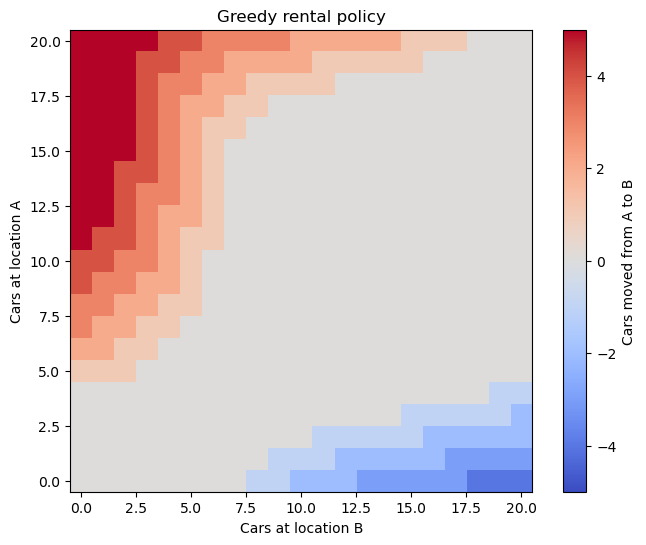

In [15]:
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(policy, origin="lower", cmap="coolwarm", vmin=-env.max_move, vmax=env.max_move)
fig.colorbar(image, ax=ax, label="Cars moved from A to B")
ax.set(xlabel="Cars at location B", ylabel="Cars at location A", title="Greedy rental policy")
plt.show()

## 6. Value function convergence

The plot shows $\delta_k$ on a logarithmic vertical axis, together with the stopping tolerance. A decreasing maximum change indicates stabilization of the value function. The final Bellman residual reported above provides a separate check of the approximate fixed point.

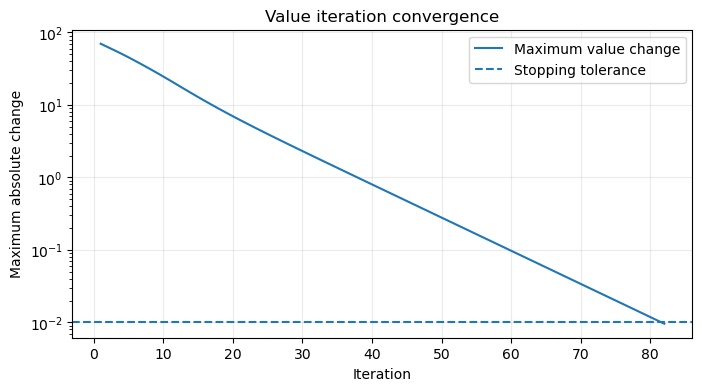

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(np.arange(1, len(solver.history) + 1), np.maximum(solver.history, np.finfo(float).tiny), label="Maximum value change")
ax.axhline(solver.tolerance, linestyle="--", label="Stopping tolerance")
ax.set(xlabel="Iteration", ylabel="Maximum absolute change", title="Value iteration convergence")
ax.legend()
ax.grid(alpha=0.25)
plt.show()